Dataset: Breast Cancer Wisconsin
Total Samples: 569
Total Features: 30

Running EBCSA with KNN
Iteration 1/30 | Best Error: 0.0276 | Selected Features: 19
Iteration 2/30 | Best Error: 0.0276 | Selected Features: 19
Iteration 3/30 | Best Error: 0.0276 | Selected Features: 19
Iteration 4/30 | Best Error: 0.0276 | Selected Features: 19
Iteration 5/30 | Best Error: 0.0276 | Selected Features: 19
Iteration 6/30 | Best Error: 0.0276 | Selected Features: 23
Iteration 7/30 | Best Error: 0.0252 | Selected Features: 18
Iteration 8/30 | Best Error: 0.0252 | Selected Features: 18
Iteration 9/30 | Best Error: 0.0252 | Selected Features: 18
Iteration 10/30 | Best Error: 0.0251 | Selected Features: 26
Iteration 11/30 | Best Error: 0.0251 | Selected Features: 26
Iteration 12/30 | Best Error: 0.0251 | Selected Features: 26
Iteration 13/30 | Best Error: 0.0226 | Selected Features: 21
Iteration 14/30 | Best Error: 0.0201 | Selected Features: 24
Iteration 15/30 | Best Error: 0.0201 | Selected Features: 24

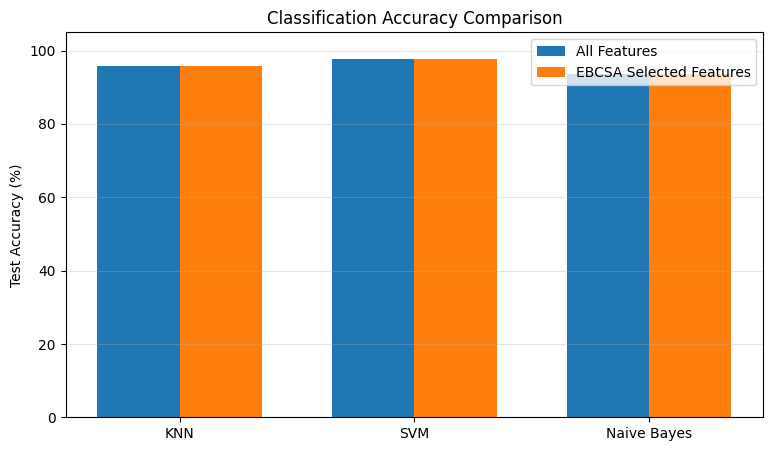

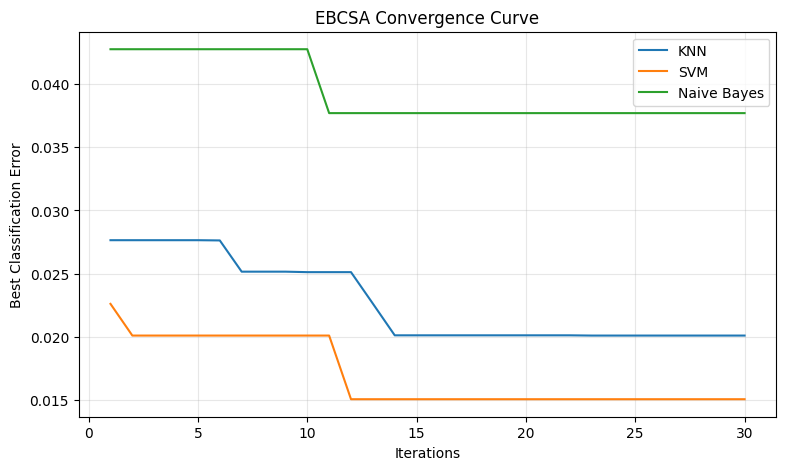


PROJECT EXECUTION COMPLETED!


In [3]:
# ============================================================
# ENHANCED BINARY CUCKOO SEARCH ALGORITHM (EBCSA)
# Based on the IEEE 2021 research paper
# Application: Feature Selection for Breast Cancer Classification
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
import math

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# ------------------------------------------------------------
# STEP 1: LOAD DATASET
# ------------------------------------------------------------

data = load_breast_cancer()

X = data.data
y = data.target
feature_names = data.feature_names

print("Dataset: Breast Cancer Wisconsin")
print("Total Samples:", X.shape[0])
print("Total Features:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# ------------------------------------------------------------
# STEP 2: CLASSIFIERS
# ------------------------------------------------------------

classifiers = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", random_state=42),
    "Naive Bayes": GaussianNB()
}

# ------------------------------------------------------------
# STEP 3: EBCSA PARAMETERS
# ------------------------------------------------------------

POP_SIZE = 20
MAX_ITER = 30
PA = 0.25
ALPHA = 0.01
BETA = 1.5

# Paper uses 30 nests, 100 iterations, PA = 0.25,
# and 10 executions. The above smaller settings make
# the first Colab demonstration faster.

# ------------------------------------------------------------
# STEP 4: BINARY CONVERSION USING SIGMOID
# ------------------------------------------------------------

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))


def binary_conversion(position):
    probability = sigmoid(position)
    return (np.random.rand(len(position)) < probability).astype(int)


# ------------------------------------------------------------
# STEP 5: LEVY FLIGHT
# ------------------------------------------------------------

def levy_flight(dimension, beta=1.5):

    sigma = (
        math.gamma(1 + beta) * np.sin(np.pi * beta / 2) /
        (
            math.gamma((1 + beta) / 2) *
            beta * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma, dimension)
    v = np.random.normal(0, 1, dimension)

    step = u / (np.abs(v) ** (1 / beta) + 1e-10)

    return step


# ------------------------------------------------------------
# STEP 6: FITNESS FUNCTION
# ------------------------------------------------------------

def fitness(solution, classifier):

    selected = np.where(solution == 1)[0]

    # At least one feature must be selected
    if len(selected) == 0:
        return 1.0

    model = make_pipeline(
        StandardScaler(),
        classifier
    )

    cv = StratifiedKFold(
        n_splits=3, shuffle=True, random_state=42
    )

    scores = cross_val_score(
        model,
        X_train[:, selected],
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    # Paper's fitness = classification error rate
    return 1 - np.mean(scores)


# ------------------------------------------------------------
# STEP 7: UNIFORM CROSSOVER
# ------------------------------------------------------------

def uniform_crossover(parent1, parent2):

    mask = np.random.randint(0, 2, len(parent1))

    child1 = np.where(mask == 1, parent1, parent2)
    child2 = np.where(mask == 1, parent2, parent1)

    return child1, child2


# ------------------------------------------------------------
# STEP 8: TWO-POINT CROSSOVER
# ------------------------------------------------------------

def two_point_crossover(parent1, parent2):

    point1, point2 = sorted(
        np.random.choice(len(parent1), 2, replace=False)
    )

    child1 = parent1.copy()
    child2 = parent2.copy()

    child1[point1:point2] = parent2[point1:point2]
    child2[point1:point2] = parent1[point1:point2]

    return child1, child2


# ------------------------------------------------------------
# STEP 9: XOR OPERATOR
# ------------------------------------------------------------

def xor_operator(o1, o2, o3, o4):

    offspring = np.bitwise_xor.reduce(
        np.array([o1, o2, o3, o4]), axis=0
    )

    # Avoid an empty feature subset
    if np.sum(offspring) == 0:
        offspring[np.random.randint(len(offspring))] = 1

    return offspring


# ------------------------------------------------------------
# STEP 10: ENHANCED BINARY CUCKOO SEARCH
# ------------------------------------------------------------

def EBCSA(classifier):

    dimension = X_train.shape[1]

    # Initialize binary population
    population = np.random.randint(
        0, 2, (POP_SIZE, dimension)
    )

    for i in range(POP_SIZE):
        if np.sum(population[i]) == 0:
            population[i, np.random.randint(dimension)] = 1

    fitness_values = np.array([
        fitness(nest, classifier) for nest in population
    ])

    best_index = np.argmin(fitness_values)
    best_nest = population[best_index].copy()
    best_fitness = fitness_values[best_index]

    convergence = []
    previous_best = best_fitness

    # Main iteration
    for iteration in range(MAX_ITER):

        for i in range(POP_SIZE):

            # Generate new solution using Levy Flight
            step = levy_flight(dimension, BETA)

            continuous_position = (
                population[i] +
                ALPHA * step * (population[i] - best_nest)
            )

            new_nest = binary_conversion(continuous_position)

            if np.sum(new_nest) == 0:
                new_nest[np.random.randint(dimension)] = 1

            # Select random nest
            j = np.random.randint(POP_SIZE)

            new_fitness = fitness(new_nest, classifier)

            # Replace nest if new solution is better
            if new_fitness < fitness_values[j]:
                population[j] = new_nest
                fitness_values[j] = new_fitness

        # Abandon worst nests based on PA
        abandon_count = max(1, int(PA * POP_SIZE))

        worst_indices = np.argsort(fitness_values)[-abandon_count:]

        for idx in worst_indices:

            population[idx] = np.random.randint(
                0, 2, dimension
            )

            if np.sum(population[idx]) == 0:
                population[idx, np.random.randint(dimension)] = 1

            fitness_values[idx] = fitness(
                population[idx], classifier
            )

        # Find best nest
        best_index = np.argmin(fitness_values)

        if fitness_values[best_index] < best_fitness:
            best_fitness = fitness_values[best_index]
            best_nest = population[best_index].copy()

        # Apply crossover when best solution stagnates
        if best_fitness >= previous_best:

            p1, p2 = random.sample(range(POP_SIZE), 2)

            parent1 = population[p1]
            parent2 = population[p2]

            # Uniform crossover
            o1, o2 = uniform_crossover(parent1, parent2)

            # Two-point crossover
            o3, o4 = two_point_crossover(parent1, parent2)

            # XOR operation
            offspring = xor_operator(o1, o2, o3, o4)

            offspring_fitness = fitness(offspring, classifier)

            # Accept better offspring
            if offspring_fitness < best_fitness:
                best_nest = offspring.copy()
                best_fitness = offspring_fitness

                worst = np.argmax(fitness_values)
                population[worst] = offspring.copy()
                fitness_values[worst] = offspring_fitness

        previous_best = best_fitness
        convergence.append(best_fitness)

        print(
            f"Iteration {iteration + 1}/{MAX_ITER} | "
            f"Best Error: {best_fitness:.4f} | "
            f"Selected Features: {np.sum(best_nest)}"
        )

    return best_nest, best_fitness, convergence


# ------------------------------------------------------------
# STEP 11: RUN EBCSA WITH THREE CLASSIFIERS
# ------------------------------------------------------------

results = {}
convergence_results = {}

for name, clf in classifiers.items():

    print("\n======================================")
    print("Running EBCSA with", name)
    print("======================================")

    selected_mask, error, convergence = EBCSA(clf)

    selected_features = np.where(selected_mask == 1)[0]

    # Train final classifier on selected features
    model = make_pipeline(
        StandardScaler(),
        clf
    )

    model.fit(
        X_train[:, selected_features],
        y_train
    )

    predictions = model.predict(
        X_test[:, selected_features]
    )

    accuracy = accuracy_score(y_test, predictions) * 100

    results[name] = {
        "Selected Features": len(selected_features),
        "Fitness Error": error,
        "Test Accuracy": accuracy,
        "Feature Names": feature_names[selected_features]
    }

    convergence_results[name] = convergence

    print("\nSelected Features:")
    print(feature_names[selected_features])

    print("\nTest Accuracy:", round(accuracy, 2), "%")
    print("Selected Feature Count:", len(selected_features))

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions,
        target_names=data.target_names
    ))

# ------------------------------------------------------------
# STEP 12: BASELINE COMPARISON (ALL FEATURES)
# ------------------------------------------------------------

print("\n========== BASELINE COMPARISON ==========")

baseline_results = {}

for name, clf in classifiers.items():

    model = make_pipeline(
        StandardScaler(),
        clf
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    baseline_accuracy = accuracy_score(
        y_test, predictions
    ) * 100

    baseline_results[name] = baseline_accuracy

    print(
        name,
        "Accuracy with all features:",
        round(baseline_accuracy, 2), "%"
    )

# ------------------------------------------------------------
# STEP 13: FINAL RESULTS TABLE
# ------------------------------------------------------------

rows = []

for name in classifiers:

    rows.append({
        "Classifier": name,
        "Accuracy (All Features)": round(
            baseline_results[name], 2
        ),
        "Accuracy (EBCSA)": round(
            results[name]["Test Accuracy"], 2
        ),
        "Selected Features": results[name]["Selected Features"],
        "Total Features": X.shape[1]
    })

result_df = pd.DataFrame(rows)

print("\n========== FINAL COMPARISON ==========")
print(result_df.to_string(index=False))

# ------------------------------------------------------------
# STEP 14: ACCURACY COMPARISON GRAPH
# ------------------------------------------------------------

x = np.arange(len(classifiers))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    [baseline_results[n] for n in classifiers],
    width,
    label="All Features"
)

plt.bar(
    x + width/2,
    [results[n]["Test Accuracy"] for n in classifiers],
    width,
    label="EBCSA Selected Features"
)

plt.xticks(x, list(classifiers.keys()))
plt.ylabel("Test Accuracy (%)")
plt.title("Classification Accuracy Comparison")
plt.legend()
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)
plt.show()

# ------------------------------------------------------------
# STEP 15: CONVERGENCE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for name, values in convergence_results.items():
    plt.plot(
        range(1, len(values) + 1),
        values,
        label=name
    )

plt.xlabel("Iterations")
plt.ylabel("Best Classification Error")
plt.title("EBCSA Convergence Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nPROJECT EXECUTION COMPLETED!")